In [19]:
%%javascript

IPython.tab_as_tab_everywhere = function(use_tabs) {
    if (use_tabs === undefined) {
        use_tabs = true; 
    }

    // apply setting to all current CodeMirror instances
    IPython.notebook.get_cells().map(
        function(c) {  return c.code_mirror.options.indentWithTabs=use_tabs;  }
    );
    // make sure new CodeMirror instances created in the future also use this setting
    CodeMirror.defaults.indentWithTabs=use_tabs;

    };

IPython.tab_as_tab_everywhere()

<IPython.core.display.Javascript object>

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import geopandas as gpd
from geovoronoi import voronoi_regions_from_coords

#from data_loader.spatial_hierarchy import SpatialHierarchy
crs = 'epsg:2165'

# GIS

In [21]:
antennas = pd.read_csv('/home/tribe/mabhishe/myspace/civ/ANT_POS.TSV', 
                          names=['id', 'lon', 'lat'], sep='\t')
antennas = antennas.groupby(['lon','lat']).first().reset_index()

antennas['wkt'] = antennas.apply(lambda r: 'POINT({} {})'.format(r['lon'], r['lat']), axis=1)
antennas['geometry'] = gpd.GeoSeries.from_wkt(antennas['wkt'])
antennas = gpd.GeoDataFrame(antennas).set_crs('epsg:4326').to_crs(crs)

antennas['x'] = antennas.geometry.apply(lambda p: p.x)
antennas['y'] = antennas.geometry.apply(lambda p: p.y)

print(antennas)

print('{} antennas'.format(len(antennas)))

           lon       lat    id                        wkt  \
0    -8.484241  6.534166  1090  POINT(-8.484241 6.534166)   
1    -8.437930  6.576323  1105   POINT(-8.43793 6.576323)   
2    -8.405955  6.457124   155  POINT(-8.405955 6.457124)   
3    -8.377062  6.491729   893  POINT(-8.377062 6.491729)   
4    -8.312376  6.768741   203  POINT(-8.312376 6.768741)   
...        ...       ...   ...                        ...   
1216 -2.801975  8.042674   230  POINT(-2.801975 8.042674)   
1217 -2.799478  8.035303   643  POINT(-2.799478 8.035303)   
1218 -2.753803  7.996683  1001  POINT(-2.753803 7.996683)   
1219 -2.722930  8.604928   706   POINT(-2.72293 8.604928)   
1220 -2.687337  8.137369  1014  POINT(-2.687337 8.137369)   

                           geometry              x              y  
0     POINT (114516.057 723121.559)  114516.056569  723121.558508  
1     POINT (119677.262 727754.763)  119677.261536  727754.763294  
2     POINT (123129.119 714530.814)  123129.119397  714530.8139

In [22]:
# linkage = 'ward'
# spatial_hierarchy = SpatialHierarchy()
# spatial_hierarchy.create_hierarchy(antennas, id_col='id', geom_col='geometry', linkage=linkage)
# #spatial_hierarchy.save_hierarchy('/Users/benoit/Desktop/Pro/211031-Madrid/out/spatial_hierarchy_civ.p')

In [23]:

# def explore(self):
#     if len(self.children)==0:
#         return  [self.name]
#     else:
#         list_nodes = []
#         for c in self.children:
#             list_nodes = list_nodes + explore(c)
#         return list_nodes
# list_nodes = explore(spatial_hierarchy.gis_root)
# 822 in list_nodes

In [24]:
# spatial_hierarchy.gis_df['id'].sort_values().values

## GIS viz

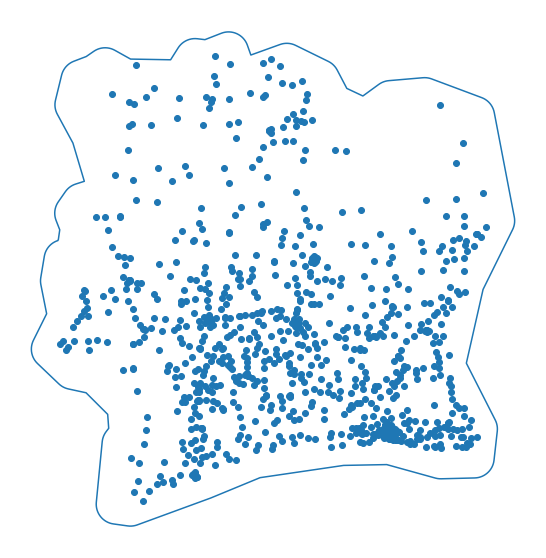

In [25]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres')).to_crs(crs)
civ_geom_df = world[world['iso_a3']=='CIV']['geometry'].buffer(30000)
civ_geom = civ_geom_df.iloc[0]

fig, ax = plt.subplots(figsize=(10,10))
antennas.plot(ax=ax)
civ_geom_df.boundary.plot(ax=ax)
ax.axis(False)
plt.show()

In [26]:
# voronoying the shit out of this
poly_shapes, pts = voronoi_regions_from_coords(np.array([antennas.x, antennas.y]).T,
                                               civ_geom)

# parsing into a nice geodataframe. pts[k][0] is the row nb, not the antenna id
voronoi_map = gpd.GeoDataFrame([[pts[k][0], poly_shapes[k]] for k in poly_shapes.keys()],
                               columns=['id', 'geometry']).set_crs('epsg:2165').sort_values('id').reset_index(drop=True)

# finding the true antenna id of each row
voronoi_map = voronoi_map.merge(antennas[['id']], left_on='id', right_index=True, suffixes=('_tmp', ''))

In [27]:
# print(max(voronoi_map.id))

In [33]:
import pickle
from pyproj import Geod
from shapely import wkt

# specify a named ellipsoid
geod = Geod(ellps="WGS84")

area_dict={}
site_id=0

for pl in voronoi_map.geometry:
# 	print(voronoi_map.iloc[site_id]['id'])
	area_dict[voronoi_map.iloc[site_id]['id']]=pl.area
	site_id=site_id+1

# area_dict[0]=1872119249.6968036
# area_dict[1222]=1872119249.6968036
print(area_dict)

with open('voronoi_area_civ.pickle', 'wb') as handle:
	pickle.dump(area_dict, handle, protocol=pickle.HIGHEST_PROTOCOL)

{1090: 1872119249.6968036, 1105: 546361031.0667813, 155: 2182770652.519763, 893: 205431076.19724965, 203: 1101670201.6697164, 876: 375385576.5153002, 472: 691317613.9909272, 1186: 236367301.58834934, 1068: 1761193250.985084, 1168: 198440036.75629112, 766: 3832775210.2305264, 333: 256676863.8923542, 1179: 253215697.50785258, 1065: 213686122.31636336, 557: 496977220.0880642, 389: 389084355.95582813, 357: 2085004451.28099, 949: 5260414565.491142, 217: 530239940.55205446, 694: 530141802.4689281, 856: 702226797.2134842, 1167: 1227974795.2314672, 989: 1070431240.4456773, 1185: 1039066617.6176962, 946: 729603698.7153919, 752: 8712031531.364456, 1003: 1904724838.3003514, 244: 4210402735.2851357, 889: 377781045.2490677, 565: 697166717.2593242, 1102: 1021944487.2346559, 1101: 721556210.8318636, 764: 515232836.3826936, 293: 2557485824.1285834, 193: 338216357.29384905, 700: 380908731.660692, 1233: 267161488.63326162, 698: 103373349.29377605, 154: 2771458889.1919656, 133: 2020320601.1148071, 942: 8

In [ ]:
voronoi_map['colorid'] = np.log(voronoi_map.area)

fig, ax = plt.subplots(figsize=(10,10))
civ_geom_df.boundary.plot(ax=ax, color='k', linewidth=0.3)
voronoi_map.boundary.plot(ax=ax, color='w', linewidth=0.3)
voronoi_map.plot(ax=ax, column='colorid')
ax.axis(False)
plt.show()

### Plotting hierarchy

In [ ]:
# spatial_hierarchy.set_map(voronoi_map)

In [ ]:
# to_plot = []
# to_plot_next = [spatial_hierarchy.gis_root]
# depth = 0
# while len(to_plot) != len(to_plot_next):
#     to_plot = to_plot_next
#     depth+=1
#     to_plot_df = gpd.GeoDataFrame([[node.name, node.geometry, node.parent_name, node.agg_level] for node in to_plot], 
#                  columns=['ci', 'geometry', 'parent', 'agg_level'])
    
#     fig, ax = plt.subplots(figsize=(10,10))
    
#     to_plot_df.plot(ax=ax, column='agg_level')
#     to_plot_df.boundary.plot(ax=ax, color='w')#, alpha=0.2, linewidth=1)
    
#     ax.axis(False)
#     plt.savefig('/Users/benoit/Desktop/Pro/211031-Madrid/out/gis_hierarchy_CoteIvoire_viz_{}/{}.png'.format(linkage, depth))
    
#     to_plot_next = []
    
#     for n in to_plot:
#         if len(n.children)==0:
#             to_plot_next += [n]
#         else:
#             to_plot_next += n.children
